<div align="center">

# COMSATS UNIVERSITY ISLAMABAD
### Department of Computer Science / Artificial Intelligence

## ARTIFICIAL NEURAL NETWORKS
### LAB 03  |  Perceptron and Weight Initialization

</div>

| **Student Information** | **Details** |
|:---|:---|
| **Name** | Ayesha Mehmood |
| **Registration No.** | FA23-BAI-010 |
| **Instructor** | Sir Zaeem Akbar Khan |
| **University** | COMSATS University Islamabad |
| **Lab Number** | Lab 03 |

---

**Instructions:** Run the code cells from top to bottom. The nine task sections follow the supplied ANN lab sheet. All saved outputs were generated by executing the code. Example values are demonstration data, not personal academic records.

**Requirements:** Python 3, NumPy, pandas, matplotlib, and scikit-learn. If needed, run %pip install numpy pandas matplotlib scikit-learn in a new cell. The datasets are bundled with scikit-learn; no separate data download is required.

## Lab Tasks


---
## Lab Task 1: Dataset Loading and Visualization

Select and load a suitable binary-classification dataset from Kaggle or the UCI Machine Learning Repository.

Perform basic data inspection, including dataset shape, features, target variable, and missing values.

Visualize the dataset using appropriate plots to understand the distribution of the classes.

Split the dataset into training and testing sets and prepare the features for model training.


The primary dataset is a real binary classification dataset from the UCI Machine Learning Repository. We retain all 30 input features. Label **0 means malignant** and label **1 means benign**. The test set is used for reporting, with no test driven choice of initialization or epoch count.

**Source:** [UCI dataset](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic) and [scikit-learn loader](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html).


Dataset: UCI Breast Cancer Wisconsin (Diagnostic)
Feature shape: (569, 30)
Feature names: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
Target labels: {0: np.str_('malignant'), 1: np.str_('benign')}
Missing feature values: 0
Missing target values: 0
First five rows:
  mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean compactness  mean concavity  mean concave points  mean symmetry  mean fractal dimension  radius error  texture error  perimet

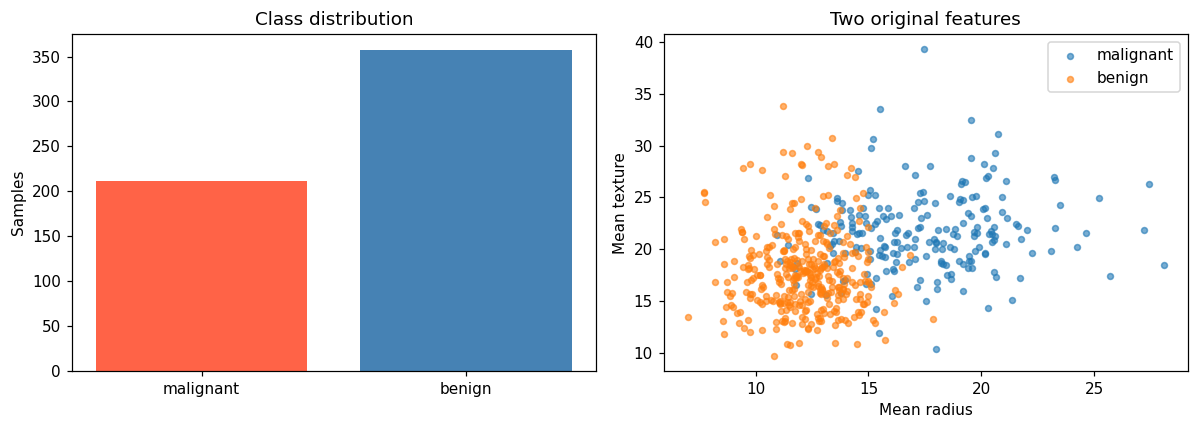

Training shape: (426, 30) Test shape: (143, 30)
Training labels: [159 267] Test labels: [53 90]


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110})

# Official UCI dataset, accessed through scikit-learn's bundled copy.
dataset = load_breast_cancer()
features = pd.DataFrame(dataset.data, columns=dataset.feature_names)
target = pd.Series(dataset.target, name="diagnosis")
print("Dataset: UCI Breast Cancer Wisconsin (Diagnostic)")
print("Feature shape:", features.shape)
print("Feature names:", list(features.columns))
print("Target labels:", dict(enumerate(dataset.target_names)))
print("Missing feature values:", int(features.isna().sum().sum()))
print("Missing target values:", int(target.isna().sum()))
print("First five rows:\n", features.head().to_string(index=False))
print("Class counts:\n", target.value_counts().sort_index().rename(index=dict(enumerate(dataset.target_names))))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts = np.bincount(dataset.target)
axes[0].bar(dataset.target_names, counts, color=["tomato", "steelblue"])
axes[0].set(title="Class distribution", ylabel="Samples")
for label, class_name in enumerate(dataset.target_names):
    selected = dataset.target == label
    axes[1].scatter(features.loc[selected, "mean radius"], features.loc[selected, "mean texture"],
                    label=class_name, alpha=0.6, s=15)
axes[1].set(xlabel="Mean radius", ylabel="Mean texture", title="Two original features")
axes[1].legend()
plt.tight_layout()
plt.show()

# Split first. Fit all scaling parameters on training samples only.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    dataset.data, dataset.target, test_size=0.25, stratify=dataset.target, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)
print("Training shape:", X_train.shape, "Test shape:", X_test.shape)
print("Training labels:", np.bincount(y_train), "Test labels:", np.bincount(y_test))


---
## Lab Task 2: Basic Perceptron Implementation

Implement a Perceptron classifier from scratch using Python and NumPy, without using a built-in Perceptron classifier.

Initialize the weights and bias and implement the perceptron prediction and weight-update rules.

Train the perceptron on the training dataset for a specified number of epochs.

Evaluate the trained perceptron on the test dataset and report its classification accuracy.


For a sample $x$, the score is $z=w^Tx+b$ and the predicted label is 1 when $z\geq0$, otherwise 0. The update is $w\leftarrow w+\eta(y-\hat y)x$ and $b\leftarrow b+\eta(y-\hat y)$.

**Convergence rule:** one complete epoch with no weight updates. A run that reaches the 100 epoch limit without this condition is reported as **not converged**, rather than being assigned a false convergence time. The history records classification error, not a differentiable loss. A linear perceptron need not converge on nonseparable data.


In [2]:
class PerceptronScratch:
    def __init__(self, learning_rate=0.01, max_epochs=100,
                 initialization="uniform", init_seed=42, shuffle_seed=99):
        self.learning_rate = learning_rate
        self.max_epochs = max_epochs
        self.initialization = initialization
        self.init_seed = init_seed
        self.shuffle_seed = shuffle_seed

    def initialize_weights(self, n_features):
        rng = np.random.default_rng(self.init_seed)
        fan_in, fan_out = n_features, 1
        if self.initialization == "uniform":
            return rng.uniform(-0.01, 0.01, n_features)
        if self.initialization == "gaussian":
            return rng.normal(0.0, 0.01, n_features)
        if self.initialization == "xavier":
            limit = np.sqrt(6.0 / (fan_in + fan_out))
            return rng.uniform(-limit, limit, n_features)
        if self.initialization == "he":
            return rng.normal(0.0, np.sqrt(2.0 / fan_in), n_features)
        if self.initialization == "orthogonal":
            # A one-output layer has an (n_features, 1) weight matrix.
            # Reduced QR produces one column with unit length: Q.T @ Q = I.
            matrix = rng.normal(size=(n_features, 1))
            q, r = np.linalg.qr(matrix, mode="reduced")
            sign = 1.0 if r[0, 0] >= 0 else -1.0
            return (q * sign)[:, 0]
        raise ValueError("Unknown initialization method")

    def predict(self, X):
        return (np.asarray(X) @ self.weights_ + self.bias_ >= 0).astype(int)

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=int)
        if set(np.unique(y)) != {0, 1}:
            raise ValueError("Training labels must contain both 0 and 1")
        self.weights_ = self.initialize_weights(X.shape[1])
        self.initial_weights_ = self.weights_.copy()
        self.bias_ = 0.0
        self.errors_, self.updates_ = [], []
        self.converged_epoch_ = None
        shuffle_rng = np.random.default_rng(self.shuffle_seed)
        for epoch in range(1, self.max_epochs + 1):
            updates = 0
            for index in shuffle_rng.permutation(len(X)):
                prediction = int(X[index] @ self.weights_ + self.bias_ >= 0)
                error = int(y[index]) - prediction
                if error != 0:
                    self.weights_ += self.learning_rate * error * X[index]
                    self.bias_ += self.learning_rate * error
                    updates += 1
            # Error is measured with the final weights of this epoch.
            self.errors_.append(float(np.mean(self.predict(X) != y)))
            self.updates_.append(updates)
            if updates == 0:
                self.converged_epoch_ = epoch
                break
        self.n_epochs_ = len(self.errors_)
        return self

settings = dict(learning_rate=0.01, max_epochs=100, init_seed=42, shuffle_seed=99)
baseline = PerceptronScratch(initialization="uniform", **settings).fit(X_train, y_train)
baseline_accuracy = np.mean(baseline.predict(X_test) == y_test)
print("Baseline test accuracy:", f"{baseline_accuracy:.2%}")
print("Epochs run:", baseline.n_epochs_)
print("Convergence epoch:", baseline.converged_epoch_)
print("Final training classification error:", f"{baseline.errors_[-1]:.4f}")


Baseline test accuracy: 95.80%
Epochs run: 100
Convergence epoch: None
Final training classification error: 0.0164


---
## Lab Task 3: Perceptron Learning Curve and Weight Visualization

Modify your perceptron implementation to record the training error/loss after every epoch.

Plot the learning curve showing the change in error over training epochs.

Display the final values of the weights and bias after training.

Visualize the final decision boundary, where applicable, and explain how it separates the two classes.


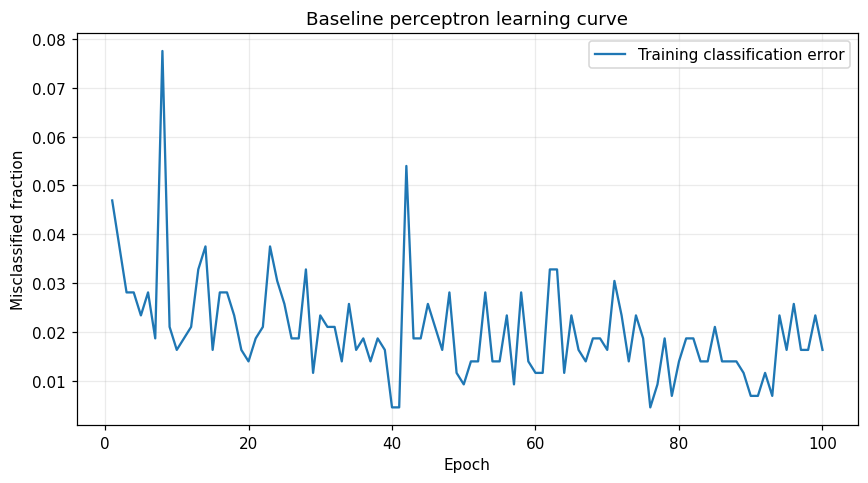

                Feature  Final weight
            mean radius     -0.004766
           mean texture     -0.002865
         mean perimeter     -0.008473
              mean area     -0.039905
        mean smoothness     -0.095149
       mean compactness      0.382510
         mean concavity     -0.166472
    mean concave points     -0.071932
          mean symmetry     -0.008772
 mean fractal dimension     -0.130792
           radius error     -0.128606
          texture error      0.052249
        perimeter error      0.063879
             area error     -0.271468
       smoothness error     -0.082397
      compactness error     -0.150797
        concavity error      0.347557
   concave points error     -0.106335
         symmetry error      0.120369
fractal dimension error      0.039232
           worst radius     -0.088586
          worst texture     -0.151046
        worst perimeter     -0.046444
             worst area     -0.195349
       worst smoothness      0.026432
      worst 

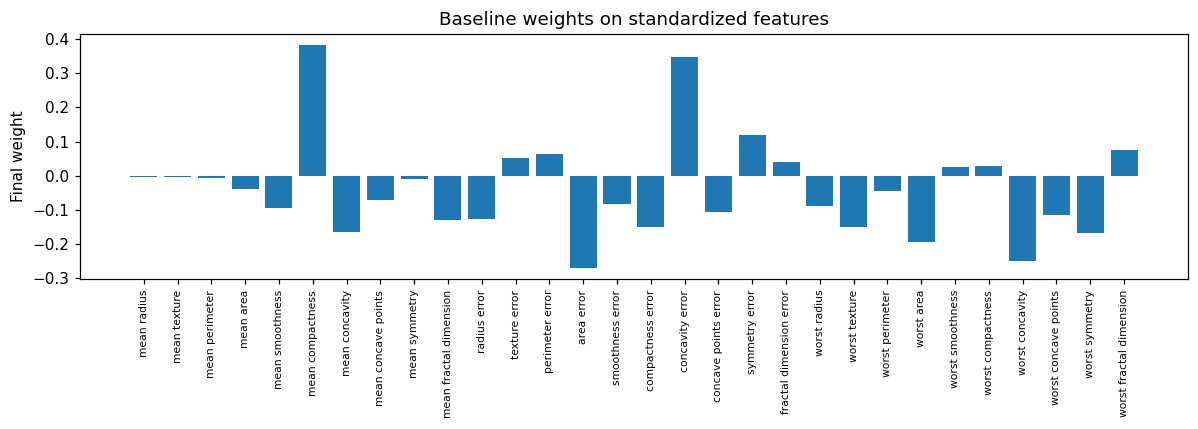

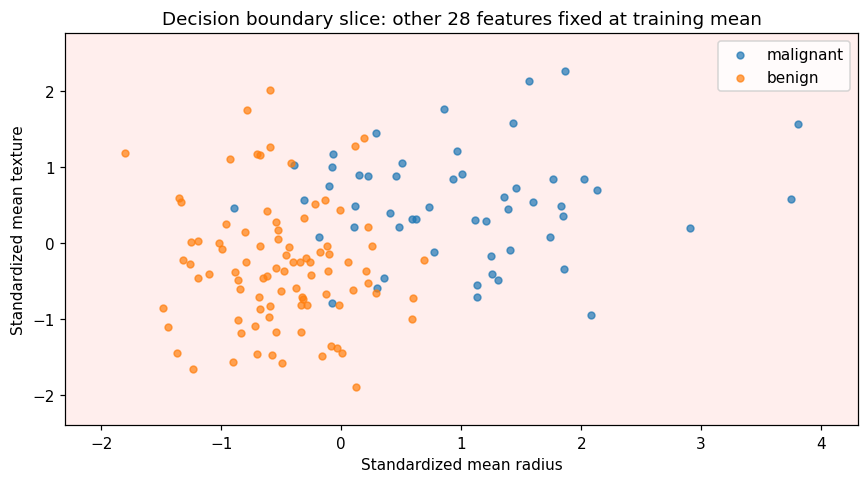

The score-zero line separates the two predicted regions in this slice.
Real test samples have 28 additional varying features; their full predictions can differ from the slice.


In [3]:
def plot_learning_curve(model, title):
    plt.figure()
    plt.plot(np.arange(1, model.n_epochs_ + 1), model.errors_, label="Training classification error")
    plt.xlabel("Epoch")
    plt.ylabel("Misclassified fraction")
    plt.title(title)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_learning_curve(baseline, "Baseline perceptron learning curve")
print(pd.DataFrame({"Feature": dataset.feature_names, "Final weight": baseline.weights_}).to_string(index=False))
print("Final bias:", baseline.bias_)
plt.figure(figsize=(11, 4))
plt.bar(np.arange(len(baseline.weights_)), baseline.weights_)
plt.xticks(np.arange(len(baseline.weights_)), dataset.feature_names, rotation=90, fontsize=7)
plt.ylabel("Final weight")
plt.title("Baseline weights on standardized features")
plt.tight_layout()
plt.show()

# Exact 2D slice of the 30D model: all other standardized inputs fixed at 0.
x0, x1 = X_test[:, 0], X_test[:, 1]
xx, yy = np.meshgrid(np.linspace(x0.min()-0.5, x0.max()+0.5, 180),
                     np.linspace(x1.min()-0.5, x1.max()+0.5, 180))
grid = np.zeros((xx.size, X_train.shape[1]))
grid[:, 0], grid[:, 1] = xx.ravel(), yy.ravel()
scores = (grid @ baseline.weights_ + baseline.bias_).reshape(xx.shape)
plt.figure()
plt.contourf(xx, yy, (scores >= 0).astype(int), levels=[-0.5, 0.5, 1.5],
             colors=["mistyrose", "lightblue"], alpha=0.6)
if scores.min() <= 0 <= scores.max():
    plt.contour(xx, yy, scores, levels=[0], colors="black", linewidths=1.5)
for label, name in enumerate(dataset.target_names):
    plt.scatter(x0[y_test == label], x1[y_test == label], label=name, s=20, alpha=0.7)
plt.xlabel("Standardized mean radius")
plt.ylabel("Standardized mean texture")
plt.title("Decision boundary slice: other 28 features fixed at training mean")
plt.legend()
plt.tight_layout()
plt.show()
print("The score-zero line separates the two predicted regions in this slice.")
print("Real test samples have 28 additional varying features; their full predictions can differ from the slice.")


---
## Lab Task 4: Gaussian Weight Initialization

Re-initialize the perceptron's weights using Gaussian/Normal initialization with a suitable mean and standard deviation.

Train the perceptron using the same dataset, hyperparameters, and training procedure used previously.

Record the number of epochs required for the perceptron to converge and plot its learning curve.

Compare the Gaussian-initialized model with the default/randomly initialized model in terms of convergence and final weights.


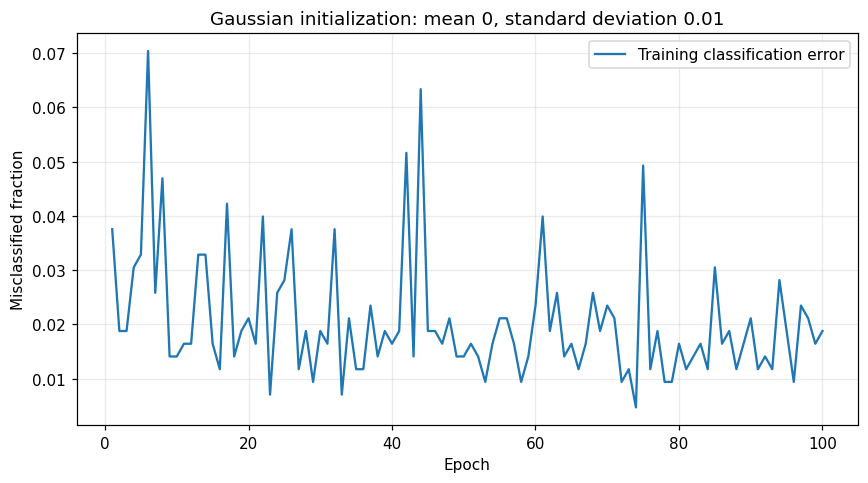

  Initialization  Epochs run  Converged Convergence epoch  Final training error  Test accuracy  Weight norm  Bias
Uniform baseline         100      False              None              0.016432       0.958042     0.815028 -0.06
        Gaussian         100      False              None              0.018779       0.965035     0.754299 -0.05
Gaussian final weights: [ 0.0126 -0.0157  0.0108 -0.02   -0.0787  0.3553 -0.1652 -0.0455  0.0421
 -0.1336 -0.1039  0.0628  0.0326 -0.2585 -0.0802 -0.1198  0.2827 -0.1585
  0.0988  0.0419 -0.0917 -0.1304 -0.0293 -0.2026  0.0535  0.0626 -0.2478
 -0.082  -0.1398  0.0698]
Gaussian final bias: -0.05
L2 distance from baseline final weights: 0.14313751033631927


In [4]:
gaussian_model = PerceptronScratch(initialization="gaussian", **settings).fit(X_train, y_train)
plot_learning_curve(gaussian_model, "Gaussian initialization: mean 0, standard deviation 0.01")

def model_record(name, model, X_eval, y_eval):
    return {"Initialization": name, "Epochs run": model.n_epochs_,
            "Converged": model.converged_epoch_ is not None,
            "Convergence epoch": model.converged_epoch_,
            "Final training error": model.errors_[-1],
            "Test accuracy": float(np.mean(model.predict(X_eval) == y_eval)),
            "Weight norm": float(np.linalg.norm(model.weights_)), "Bias": model.bias_}

print(pd.DataFrame([model_record("Uniform baseline", baseline, X_test, y_test),
                    model_record("Gaussian", gaussian_model, X_test, y_test)]).to_string(index=False))
print("Gaussian final weights:", gaussian_model.weights_)
print("Gaussian final bias:", gaussian_model.bias_)
print("L2 distance from baseline final weights:", np.linalg.norm(gaussian_model.weights_ - baseline.weights_))


---
## Lab Task 5: Xavier/Glorot Initialization

Implement Xavier/Glorot initialization for the perceptron's weights.

Train the perceptron using Xavier-initialized weights while keeping the dataset and training settings unchanged.

Record the number of epochs required for convergence and plot the corresponding learning curve.

Compare the results with Gaussian initialization and discuss how the initialization affected the training process.


For one output, Xavier uniform initialization draws each weight from $U[-a,a]$, where $a=\sqrt{6/(n_{in}+1)}$. Its original variance preservation argument concerns multilayer differentiable networks. Here it is an initialization experiment on a threshold perceptron, so an advantage is not guaranteed.


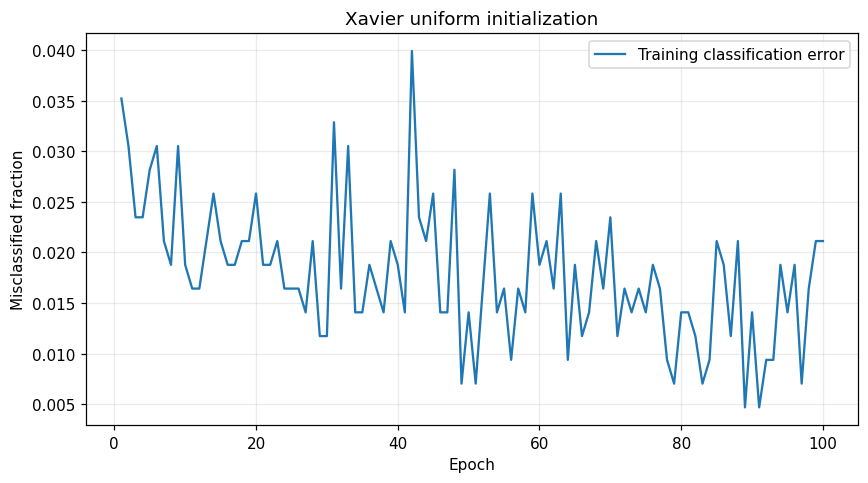

Xavier bound: 0.43994134506405985
Initialization  Epochs run  Converged Convergence epoch  Final training error  Test accuracy  Weight norm  Bias
      Gaussian         100      False              None              0.018779       0.965035     0.754299 -0.05
        Xavier         100      False              None              0.021127       0.951049     1.179019 -0.06
Xavier final weights: [-0.018   0.0228  0.0126 -0.1711 -0.1393  0.6509 -0.3018  0.0404  0.0229
 -0.2964 -0.3287  0.1197 -0.0399 -0.1924 -0.0458 -0.164   0.4046 -0.0891
  0.1287  0.0604 -0.0706 -0.2374  0.0681 -0.1339  0.074  -0.0326 -0.3381
 -0.2597 -0.2448  0.1471]
Xavier final bias: -0.06000000000000003
L2 distance between Gaussian and Xavier final weights: 0.5907234223251387


In [5]:
xavier_model = PerceptronScratch(initialization="xavier", **settings).fit(X_train, y_train)
plot_learning_curve(xavier_model, "Xavier uniform initialization")
print("Xavier bound:", np.sqrt(6.0 / (X_train.shape[1] + 1)))
print(pd.DataFrame([model_record("Gaussian", gaussian_model, X_test, y_test),
                    model_record("Xavier", xavier_model, X_test, y_test)]).to_string(index=False))
print("Xavier final weights:", xavier_model.weights_)
print("Xavier final bias:", xavier_model.bias_)
print("L2 distance between Gaussian and Xavier final weights:",
      np.linalg.norm(gaussian_model.weights_ - xavier_model.weights_))


---
## Lab Task 6: He/Kaiming Initialization

Implement He/Kaiming initialization for the perceptron's weights.

Train the perceptron using the He-initialized weights on the same training dataset.

Record the convergence behavior, number of epochs, final weights, and test accuracy.

Compare the He initialization results with Gaussian and Xavier initialization.


He normal initialization uses standard deviation $\sqrt{2/n_{in}}$. It was designed for rectifier networks. This single threshold neuron does not use ReLU, so these measurements do not establish the usual deep network benefit of He initialization.


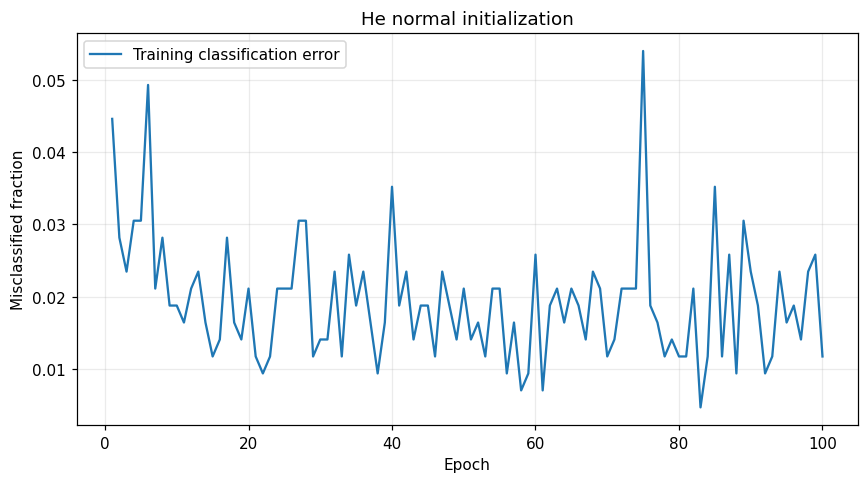

He standard deviation: 0.2581988897471611
Initialization  Epochs run  Converged Convergence epoch  Final training error  Test accuracy  Weight norm  Bias
      Gaussian         100      False              None              0.018779       0.965035     0.754299 -0.05
        Xavier         100      False              None              0.021127       0.951049     1.179019 -0.06
            He         100      False              None              0.011737       0.951049     0.890156 -0.05
He final weights: [-0.0698 -0.0033  0.0678  0.0238 -0.0876  0.392  -0.1957 -0.0744  0.016
 -0.122  -0.12    0.0526 -0.0201 -0.1335 -0.0908 -0.1632  0.3623 -0.1369
  0.1141  0.0199 -0.257  -0.1362  0.1521 -0.3682 -0.007   0.0432 -0.2238
 -0.082  -0.151   0.0596]
He final bias: -0.05


In [6]:
he_model = PerceptronScratch(initialization="he", **settings).fit(X_train, y_train)
plot_learning_curve(he_model, "He normal initialization")
print("He standard deviation:", np.sqrt(2.0 / X_train.shape[1]))
print(pd.DataFrame([model_record(name, model, X_test, y_test) for name, model in
                    [("Gaussian", gaussian_model), ("Xavier", xavier_model), ("He", he_model)]]).to_string(index=False))
print("He final weights:", he_model.weights_)
print("He final bias:", he_model.bias_)


---
## Lab Task 7: Orthogonal Initialization

Implement Orthogonal initialization for the perceptron's weight matrix.

Train the perceptron using the orthogonally initialized weights while keeping all other experimental settings consistent.

Plot the learning curve and record the number of epochs required for convergence.

Compare Orthogonal initialization with Gaussian, Xavier, and He initialization based on convergence behavior and final model parameters.


A single output has only one weight column. Orthogonal initialization therefore means a randomly oriented unit column; there are no multiple columns whose mutual orthogonality could be compared. Training does not preserve that unit length constraint.


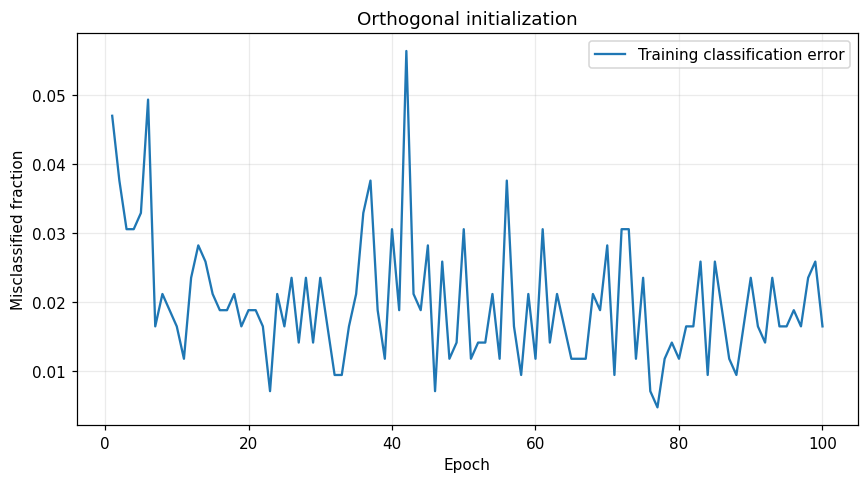

Initial weight matrix shape: (30, 1)
Initial W.T @ W: [[1.]]
Unit column verified: True
Orthogonal final weights: [-0.0571 -0.0166  0.0672  0.0214 -0.0694  0.3658 -0.178  -0.0472  0.0147
 -0.1201 -0.0996  0.0601 -0.0468 -0.1443 -0.1025 -0.1796  0.35   -0.1411
  0.0976  0.0338 -0.241  -0.1171  0.123  -0.3658  0.0055  0.0361 -0.2155
 -0.0781 -0.1497  0.044 ]
Orthogonal final bias: -0.05
Initialization  Epochs run  Converged Convergence epoch  Final training error  Test accuracy  Weight norm  Bias
      Gaussian         100      False              None              0.018779       0.965035     0.754299 -0.05
        Xavier         100      False              None              0.021127       0.951049     1.179019 -0.06
            He         100      False              None              0.011737       0.951049     0.890156 -0.05
    Orthogonal         100      False              None              0.016432       0.958042     0.852619 -0.05


In [7]:
orthogonal_model = PerceptronScratch(initialization="orthogonal", **settings).fit(X_train, y_train)
plot_learning_curve(orthogonal_model, "Orthogonal initialization")
initial_column = orthogonal_model.initial_weights_.reshape(-1, 1)
print("Initial weight matrix shape:", initial_column.shape)
print("Initial W.T @ W:", initial_column.T @ initial_column)
print("Unit column verified:", np.allclose(initial_column.T @ initial_column, np.eye(1)))
print("Orthogonal final weights:", orthogonal_model.weights_)
print("Orthogonal final bias:", orthogonal_model.bias_)
models = {"Gaussian": gaussian_model, "Xavier": xavier_model,
          "He": he_model, "Orthogonal": orthogonal_model}
print(pd.DataFrame([model_record(name, model, X_test, y_test)
                    for name, model in models.items()]).to_string(index=False))


---
## Lab Task 8: Comparative Analysis of Weight Initialization Techniques

Train the same perceptron using Gaussian, Xavier, He, and Orthogonal initialization on the same dataset.

Record the number of epochs, final training error, test accuracy, and final weight values for each initialization technique.

Plot the learning curves of all initialization techniques and compare their convergence behavior.

Write a short analysis explaining why different initialization techniques may produce different training behavior.


Single fixed split and seed comparison:
 Initialization  Epochs run  Converged Convergence epoch  Final training error  Test accuracy  Weight norm  Bias
      Gaussian         100      False              None              0.018779       0.965035     0.754299 -0.05
        Xavier         100      False              None              0.021127       0.951049     1.179019 -0.06
            He         100      False              None              0.011737       0.951049     0.890156 -0.05
    Orthogonal         100      False              None              0.016432       0.958042     0.852619 -0.05
Final weight values:
                          Gaussian    Xavier        He  Orthogonal
mean radius              0.012560 -0.018043 -0.069827   -0.057074
mean texture            -0.015678  0.022798 -0.003350   -0.016595
mean perimeter           0.010789  0.012566  0.067781    0.067232
mean area               -0.020003 -0.171086  0.023844    0.021371
mean smoothness         -0.078656 -0.139297 -0.

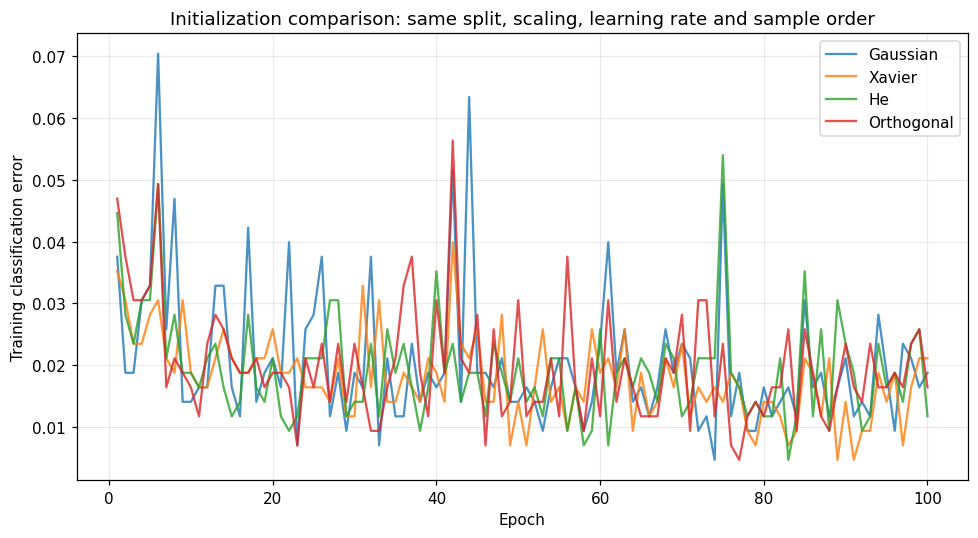

Gaussian: did not converge within 100 epochs; test accuracy 96.50%; final error 0.0188.
Xavier: did not converge within 100 epochs; test accuracy 95.10%; final error 0.0211.
He: did not converge within 100 epochs; test accuracy 95.10%; final error 0.0117.
Orthogonal: did not converge within 100 epochs; test accuracy 95.80%; final error 0.0164.
Different initial directions and scales change the first mistakes and later updates.
A perceptron error curve can fluctuate because each update can correct some samples and misclassify others.
This one split and seed does not establish a universally best initializer.


In [8]:
comparison = pd.DataFrame([model_record(name, model, X_test, y_test)
                           for name, model in models.items()])
print("Single fixed split and seed comparison:\n", comparison.to_string(index=False))
weights_table = pd.DataFrame({name: model.weights_ for name, model in models.items()},
                             index=dataset.feature_names)
print("Final weight values:\n", weights_table.to_string())
plt.figure(figsize=(9, 5))
for name, model in models.items():
    plt.plot(np.arange(1, model.n_epochs_ + 1), model.errors_, label=name, alpha=0.8)
plt.xlabel("Epoch")
plt.ylabel("Training classification error")
plt.title("Initialization comparison: same split, scaling, learning rate and sample order")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
for row in comparison.to_dict("records"):
    status = f"converged in {int(row['Convergence epoch'])} epochs" if row['Converged'] else "did not converge within 100 epochs"
    print(f"{row['Initialization']}: {status}; test accuracy {row['Test accuracy']:.2%}; final error {row['Final training error']:.4f}.")
print("Different initial directions and scales change the first mistakes and later updates.")
print("A perceptron error curve can fluctuate because each update can correct some samples and misclassify others.")
print("This one split and seed does not establish a universally best initializer.")


---
## Lab Task 9: Experimental Study and Interpretation

Select a different suitable binary-classification dataset and repeat the perceptron experiment using Gaussian, Xavier, He, and Orthogonal initialization.

Conduct multiple training runs for each initialization technique using different random seeds.

Calculate and compare the average convergence epochs and average test accuracy across the runs.

Based on your experimental results, discuss how weight initialization, dataset characteristics, and randomness can influence perceptron training.


Repeat every method on a second dataset, using five paired seeds. The original Wine dataset has three classes; filtering to its first two cultivars creates a disclosed binary classification experiment. We also repeat the primary dataset so both datasets have comparable seed summaries. [UCI Wine source](https://archive.ics.uci.edu/dataset/109/wine).


Secondary dataset: UCI Wine, restricted to original labels 0 and 1
Binary subset shape: (130, 13) Class counts: [59 71]
Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Missing values: 0
Individual training runs:
 Initialization  Epochs run  Converged  Convergence epoch  Final training error  Test accuracy  Weight norm  Bias            Dataset  Seed
      Gaussian         100      False                NaN              0.016432       0.958042     0.812851 -0.05      Breast cancer     1
        Xavier         100      False                NaN              0.016432       0.965035     1.062344 -0.02      Breast cancer     1
            He         100      False                NaN              0.018779       0.958042     0.963203 -0.05      Breast cancer     1
    Orthogonal         100      False                NaN  

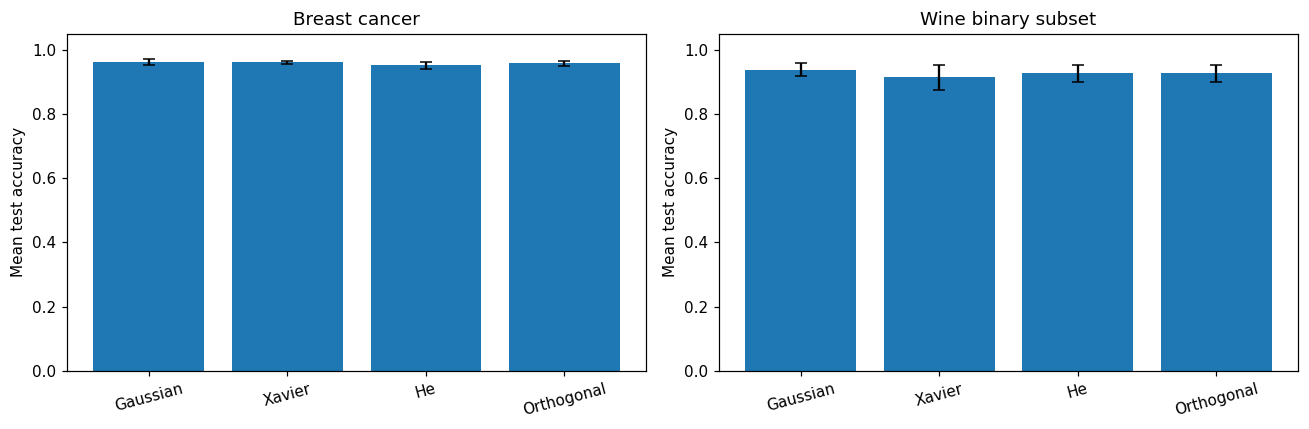

Breast cancer: mean accuracies range from 95.24% to 96.36%; 0/20 runs converged.
Wine binary subset: mean accuracies range from 91.52% to 93.94%; 20/20 runs converged.
Initialization changes the starting hyperplane; shuffled order changes the update sequence.
Feature geometry, class overlap and linear separability affect whether zero-update convergence is possible.
The split is fixed, so the standard deviations describe training randomness, not uncertainty over new data splits.
No initialization was selected using the test set. These results are descriptive comparisons.


In [9]:
# Different UCI dataset: use two wine cultivars to form an explicit binary task.
wine = load_wine()
binary_mask = wine.target < 2
wine_X, wine_y = wine.data[binary_mask], wine.target[binary_mask]
print("Secondary dataset: UCI Wine, restricted to original labels 0 and 1")
print("Binary subset shape:", wine_X.shape, "Class counts:", np.bincount(wine_y))
print("Feature names:", list(wine.feature_names))
print("Missing values:", int(np.isnan(wine_X).sum()))

def prepare_split(X, y):
    a, b, ya, yb = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
    transform = StandardScaler().fit(a)
    return transform.transform(a), transform.transform(b), ya, yb

wine_split = prepare_split(wine_X, wine_y)
seed_values = [1, 7, 21, 42, 99]
run_rows = []
for data_name, split in [("Breast cancer", (X_train, X_test, y_train, y_test)),
                          ("Wine binary subset", wine_split)]:
    train_X, test_X, train_y, test_y = split
    for seed in seed_values:
        for method in ["gaussian", "xavier", "he", "orthogonal"]:
            # Same sample order for all methods within a seed; independent
            # initialization and shuffle generators prevent RNG confounding.
            model = PerceptronScratch(learning_rate=0.01, max_epochs=100,
                initialization=method, init_seed=seed, shuffle_seed=seed + 1000).fit(train_X, train_y)
            row = model_record(method.title(), model, test_X, test_y)
            row.update({"Dataset": data_name, "Seed": seed})
            run_rows.append(row)
runs = pd.DataFrame(run_rows)
print("Individual training runs:\n", runs.to_string(index=False))
summary = runs.groupby(["Dataset", "Initialization"], sort=False).agg(
    Runs=("Seed", "size"), Converged_runs=("Converged", "sum"),
    Mean_convergence_epochs=("Convergence epoch", "mean"),
    Mean_epochs_run=("Epochs run", "mean"),
    Mean_test_accuracy=("Test accuracy", "mean"),
    SD_test_accuracy=("Test accuracy", "std"),
    Mean_final_training_error=("Final training error", "mean")).reset_index()
print("\nMulti-seed summary:\n", summary.to_string(index=False))
print("Convergence means exclude nonconverged runs; NaN means no run converged.")
print("Mean epochs run includes every run and is not a convergence estimate.")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (data_name, block) in zip(axes, summary.groupby("Dataset", sort=False)):
    ax.bar(block["Initialization"], block["Mean_test_accuracy"],
           yerr=block["SD_test_accuracy"].fillna(0), capsize=4)
    ax.set(title=data_name, ylabel="Mean test accuracy", ylim=(0, 1.05))
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()
for data_name, block in summary.groupby("Dataset", sort=False):
    print(f"{data_name}: mean accuracies range from {block.Mean_test_accuracy.min():.2%} to {block.Mean_test_accuracy.max():.2%}; "
          f"{int(block.Converged_runs.sum())}/{int(block.Runs.sum())} runs converged.")
print("Initialization changes the starting hyperplane; shuffled order changes the update sequence.")
print("Feature geometry, class overlap and linear separability affect whether zero-update convergence is possible.")
print("The split is fixed, so the standard deviations describe training randomness, not uncertainty over new data splits.")
print("No initialization was selected using the test set. These results are descriptive comparisons.")


**Interpretation:** Compare the printed convergence counts before comparing mean convergence time. A method that converges once is not necessarily faster than a method that converges in every run. Training error and test accuracy answer different questions. These small experiments do not prove one initialization is best for all datasets.

**Initialization references:** [Glorot and Bengio, 2010](https://proceedings.mlr.press/v9/glorot10a.html); [He et al., 2015](https://arxiv.org/abs/1502.01852); [Saxe et al., 2013](https://arxiv.org/abs/1312.6120).
